
TASK 1: CREDIT SCORING MODEL
Dataset shape: (6000, 10)
Class balance (0 = bad, 1 = good):
good_credit
0    0.646
1    0.354

Model comparison (test set):
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.7142     0.5722  0.7647    0.6546   0.7964
Decision Tree          0.6475     0.5016  0.7412    0.5983   0.7234
Random Forest          0.7167     0.5822  0.7082    0.6391   0.7769

Best model by ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

  Bad credit       0.84      0.69      0.76       775
 Good credit       0.57      0.76      0.65       425

    accuracy                           0.71      1200
   macro avg       0.71      0.73      0.71      1200
weighted avg       0.75      0.71      0.72      1200



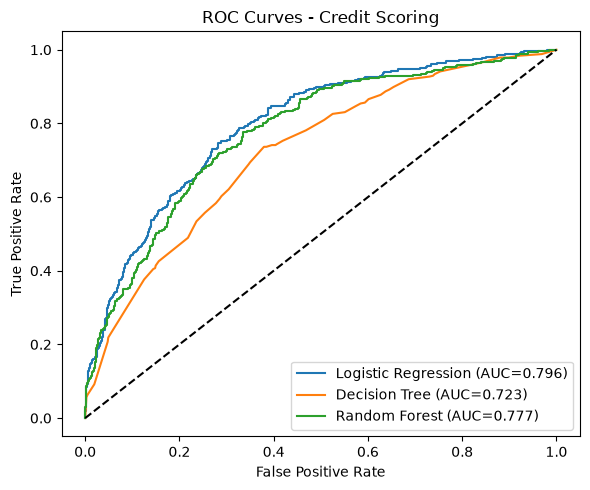

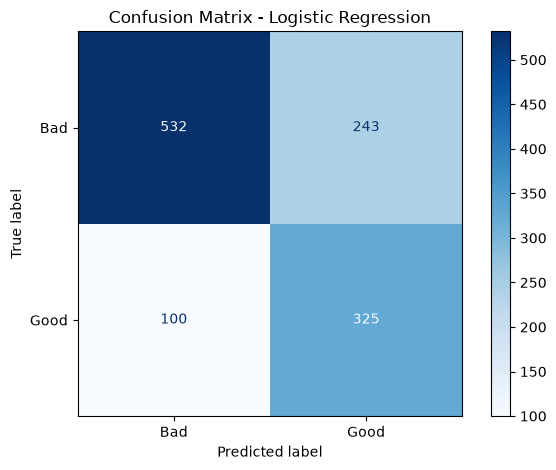

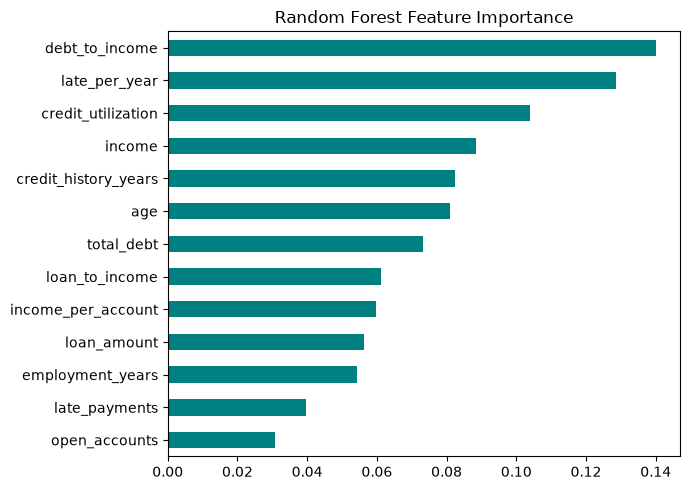

Top features:
debt_to_income          0.1400
late_per_year           0.1285
credit_utilization      0.1040
income                  0.0885
credit_history_years    0.0824

TASK 3: HANDWRITTEN CHARACTER RECOGNITION
Images: 1797 | image size: 8x8 | classes: 10


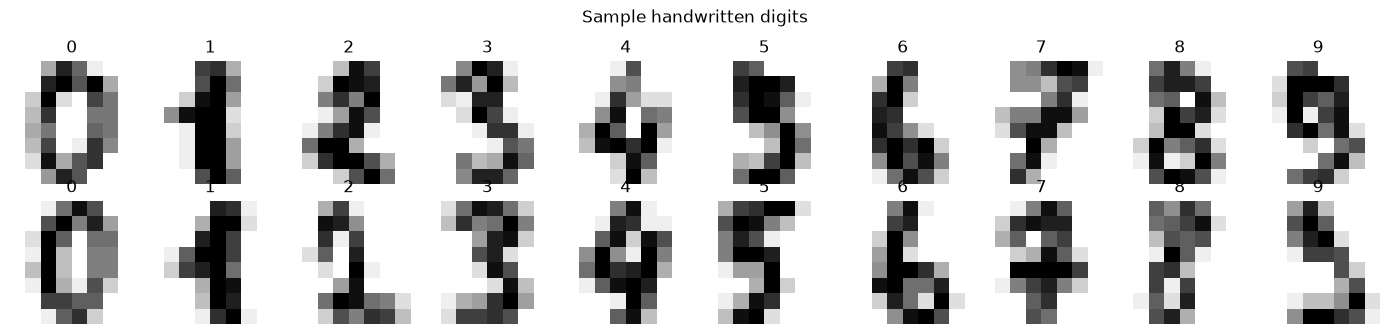

SVM (RBF)              test accuracy: 0.9889
Neural Network (MLP)   test accuracy: 0.9667
Random Forest          test accuracy: 0.9694

Best model: SVM (RBF)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       0.97      0.94      0.96        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



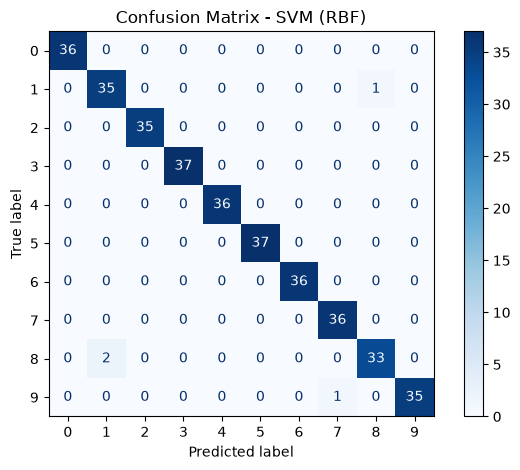

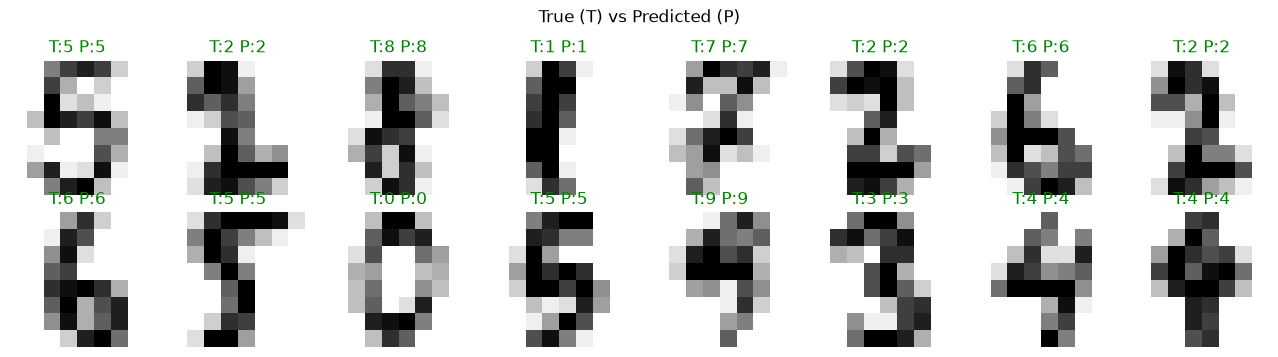


TASK 4: DISEASE PREDICTION FROM MEDICAL DATA
Dataset shape: (569, 30) | malignant: 212 | benign: 357
Missing values: 0
Best SVM parameters: {'m__C': 10, 'm__gamma': 0.01}

Model comparison:
                     CV Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                                
SVM                       0.9758         0.9825     0.9861  0.9861    0.9861   0.9977
Logistic Regression       0.9780         0.9825     0.9861  0.9861    0.9861   0.9954
Random Forest             0.9648         0.9474     0.9583  0.9583    0.9583   0.9937
Gradient Boosting         0.9516         0.9561     0.9467  0.9861    0.9660   0.9907

Best model: SVM
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weig

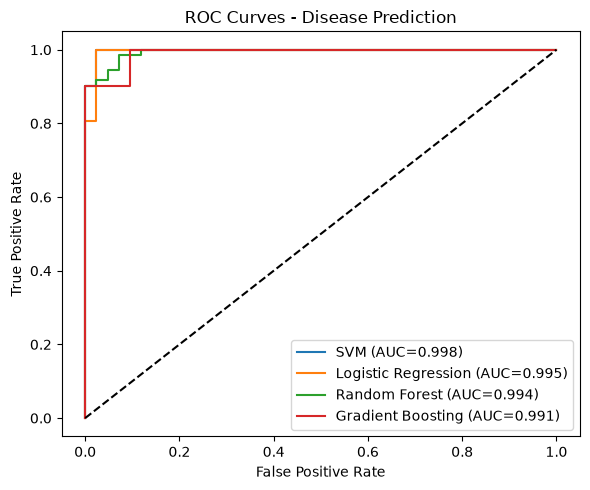

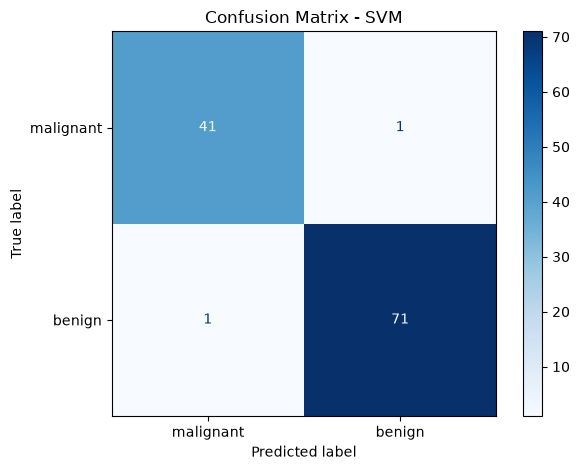

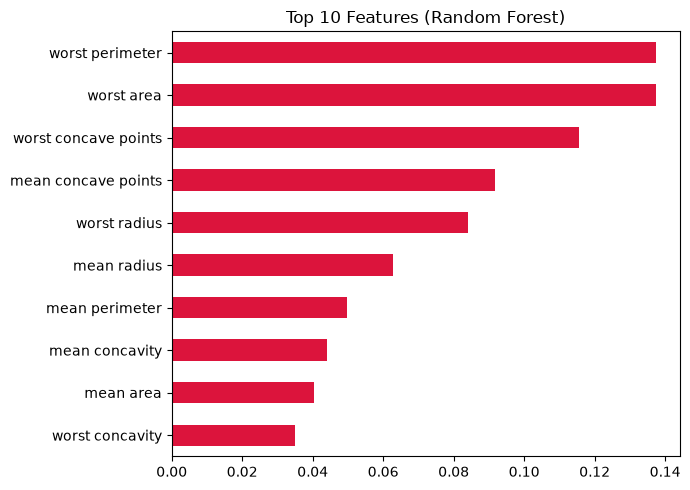

Top features:
worst perimeter         0.1373
worst area              0.1373
worst concave points    0.1155
mean concave points     0.0918
worst radius            0.0841

All tasks finished. Results and graphs are in the folder: C:\Users\NLH\Desktop\mechine learning\CodeAlpha Tasks\CodeAlpha_Output


In [1]:
"""

Mechine learning Tasks Give by Code ALpha That i have completed


Task 1: Credit Scoring Model
Task 3: Handwritten Character Recognition
Task 4: Disease Prediction from Medical Data

"""
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.datasets import load_digits, load_breast_cancer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
OUT = "CodeAlpha_Output"
os.makedirs(OUT, exist_ok=True)


def in_jupyter():
    try:
        return get_ipython().__class__.__name__ == "ZMQInteractiveShell"
    except NameError:
        return False


def save_fig(folder, name):
    """Save the current figure; show it only inside Jupyter (so scripts never freeze)."""
    path = os.path.join(OUT, folder)
    os.makedirs(path, exist_ok=True)
    plt.tight_layout()
    plt.savefig(os.path.join(path, name), dpi=150)
    if in_jupyter():
        plt.show()
    plt.close()


def header(text):
    print("\n" + "=" * 70 + "\n" + text + "\n" + "=" * 70)


# =====================================================================
# TASK 1 - CREDIT SCORING MODEL
# =====================================================================
def make_credit_data(n=6000, seed=SEED):
    rng = np.random.default_rng(seed)
    age = rng.integers(21, 70, n)
    income = np.clip(rng.lognormal(10.8, 0.5, n), 12000, 400000)
    total_debt = income * rng.beta(2, 4, n) * 1.5
    credit_utilization = np.clip(rng.beta(2, 3, n), 0, 1)
    late_payments = rng.poisson(1.2, n)
    credit_history_years = np.clip(age - 18 - rng.integers(0, 10, n), 0, 45)
    open_accounts = rng.integers(1, 15, n)
    loan_amount = np.clip(income * rng.uniform(0.1, 1.2, n), 1000, None)
    employment_years = np.clip(rng.gamma(2.5, 3, n), 0, age - 18)

    score = (1.2 + 0.000012 * (income - 60000) - 2.6 * (total_debt / income)
             - 2.2 * credit_utilization - 0.55 * late_payments
             + 0.05 * credit_history_years + 0.04 * employment_years
             - 0.8 * (loan_amount / income) + rng.normal(0, 0.8, n))
    good = (1 / (1 + np.exp(-score)) > rng.uniform(0, 1, n)).astype(int)

    return pd.DataFrame({
        "age": age, "income": income.round(0), "total_debt": total_debt.round(0),
        "credit_utilization": credit_utilization.round(3), "late_payments": late_payments,
        "credit_history_years": credit_history_years, "open_accounts": open_accounts,
        "loan_amount": loan_amount.round(0), "employment_years": employment_years.round(1),
        "good_credit": good})


def task1_credit_scoring(csv_path=None, target="good_credit"):
    header("TASK 1: CREDIT SCORING MODEL")
    df = pd.read_csv(csv_path) if csv_path else make_credit_data()
    print("Dataset shape:", df.shape)
    print("Class balance (0 = bad, 1 = good):")
    print(df[target].value_counts(normalize=True).round(3).to_string())

    # Feature engineering from financial history
    if {"total_debt", "income"} <= set(df.columns):
        df["debt_to_income"] = df["total_debt"] / df["income"].replace(0, np.nan)
    if {"loan_amount", "income"} <= set(df.columns):
        df["loan_to_income"] = df["loan_amount"] / df["income"].replace(0, np.nan)
    if {"late_payments", "credit_history_years"} <= set(df.columns):
        df["late_per_year"] = df["late_payments"] / (df["credit_history_years"] + 1)
    if {"income", "open_accounts"} <= set(df.columns):
        df["income_per_account"] = df["income"] / (df["open_accounts"] + 1)
    df = df.fillna(df.median(numeric_only=True))

    X, y = df.drop(columns=[target]), df[target]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

    models = {
        "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                         ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                                                class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                                class_weight="balanced", n_jobs=-1, random_state=SEED),
    }
    rows, probs = [], {}
    for name, m in models.items():
        m.fit(X_tr, y_tr)
        pred, proba = m.predict(X_te), m.predict_proba(X_te)[:, 1]
        probs[name] = proba
        rows.append({"Model": name, "Accuracy": accuracy_score(y_te, pred),
                     "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                     "F1-Score": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba)})
    res = pd.DataFrame(rows).set_index("Model").round(4)
    print("\nModel comparison (test set):")
    print(res.to_string())
    os.makedirs(os.path.join(OUT, "Task1_CreditScoring"), exist_ok=True)
    res.to_csv(os.path.join(OUT, "Task1_CreditScoring", "model_comparison.csv"))

    best = res["ROC-AUC"].idxmax()
    print("\nBest model by ROC-AUC:", best)
    print(classification_report(y_te, models[best].predict(X_te), target_names=["Bad credit", "Good credit"]))

    plt.figure(figsize=(6, 5))
    for name, p in probs.items():
        f, t, _ = roc_curve(y_te, p)
        plt.plot(f, t, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("ROC Curves - Credit Scoring"); plt.legend()
    save_fig("Task1_CreditScoring", "roc_curves.png")

    ConfusionMatrixDisplay(confusion_matrix(y_te, models[best].predict(X_te)),
                           display_labels=["Bad", "Good"]).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {best}")
    save_fig("Task1_CreditScoring", "confusion_matrix.png")

    imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
    imp.plot(kind="barh", figsize=(7, 5), color="teal")
    plt.title("Random Forest Feature Importance")
    save_fig("Task1_CreditScoring", "feature_importance.png")
    print("Top features:")
    print(imp.sort_values(ascending=False).head(5).round(4).to_string())


# =====================================================================
# TASK 3 - HANDWRITTEN CHARACTER (DIGIT) RECOGNITION
# =====================================================================
def task3_handwritten():
    header("TASK 3: HANDWRITTEN CHARACTER RECOGNITION")
    digits = load_digits()
    X, y = digits.data / 16.0, digits.target
    print("Images:", X.shape[0], "| image size: 8x8 | classes:", len(np.unique(y)))

    fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
    for i, ax in enumerate(axes.ravel()):
        ax.imshow(digits.images[i], cmap="gray_r"); ax.set_title(digits.target[i]); ax.axis("off")
    plt.suptitle("Sample handwritten digits")
    save_fig("Task3_Handwritten", "sample_digits.png")

    X_tr, X_te, y_tr, y_te, _, img_te = train_test_split(
        X, y, digits.images, test_size=0.2, stratify=y, random_state=SEED)

    models = {
        "SVM (RBF)": SVC(C=10, gamma=0.02, random_state=SEED),
        "Neural Network (MLP)": Pipeline([("sc", StandardScaler()),
            ("m", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500,
                                early_stopping=True, random_state=SEED))]),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    }
    accs = {}
    for name, m in models.items():
        m.fit(X_tr, y_tr)
        accs[name] = accuracy_score(y_te, m.predict(X_te))
        print(f"{name:22s} test accuracy: {accs[name]:.4f}")
    os.makedirs(os.path.join(OUT, "Task3_Handwritten"), exist_ok=True)
    pd.Series(accs, name="Test Accuracy").round(4).to_csv(
        os.path.join(OUT, "Task3_Handwritten", "model_comparison.csv"))

    best = max(accs, key=accs.get)
    pred = models[best].predict(X_te)
    print("\nBest model:", best)
    print(classification_report(y_te, pred))

    ConfusionMatrixDisplay(confusion_matrix(y_te, pred)).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {best}")
    save_fig("Task3_Handwritten", "confusion_matrix.png")

    fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
    for ax, im, t, p in zip(axes.ravel(), img_te, y_te, pred):
        ax.imshow(im, cmap="gray_r"); ax.axis("off")
        ax.set_title(f"T:{t} P:{p}", color="green" if t == p else "red")
    plt.suptitle("True (T) vs Predicted (P)")
    save_fig("Task3_Handwritten", "predictions.png")


# =====================================================================
# TASK 4 - DISEASE PREDICTION (BREAST CANCER, UCI DATASET)
# =====================================================================
def task4_disease():
    header("TASK 4: DISEASE PREDICTION FROM MEDICAL DATA")
    data = load_breast_cancer(as_frame=True)
    X, y = data.data, data.target          # 0 = malignant, 1 = benign
    print("Dataset shape:", X.shape, "| malignant:", int((y == 0).sum()), "| benign:", int((y == 1).sum()))
    print("Missing values:", int(X.isna().sum().sum()))

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

    svm = Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=SEED))])
    grid = GridSearchCV(svm, {"m__C": [0.1, 1, 10, 100], "m__gamma": ["scale", 0.01, 0.001]},
                        cv=cv, scoring="roc_auc").fit(X_tr, y_tr)
    print("Best SVM parameters:", grid.best_params_)

    models = {
        "SVM": grid.best_estimator_,
        "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=3000))]),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    }
    rows, probs = [], {}
    for name, m in models.items():
        cv_acc = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="accuracy").mean()
        m.fit(X_tr, y_tr)
        pred, proba = m.predict(X_te), m.predict_proba(X_te)[:, 1]
        probs[name] = proba
        rows.append({"Model": name, "CV Accuracy": cv_acc, "Test Accuracy": accuracy_score(y_te, pred),
                     "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                     "F1-Score": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba)})
    res = pd.DataFrame(rows).set_index("Model").round(4)
    print("\nModel comparison:")
    print(res.to_string())
    os.makedirs(os.path.join(OUT, "Task4_DiseasePrediction"), exist_ok=True)
    res.to_csv(os.path.join(OUT, "Task4_DiseasePrediction", "model_comparison.csv"))

    best = res["ROC-AUC"].idxmax()
    print("\nBest model:", best)
    print(classification_report(y_te, models[best].predict(X_te), target_names=data.target_names))

    plt.figure(figsize=(6, 5))
    for n, p in probs.items():
        f, t, _ = roc_curve(y_te, p)
        plt.plot(f, t, label=f"{n} (AUC={roc_auc_score(y_te, p):.3f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("ROC Curves - Disease Prediction"); plt.legend()
    save_fig("Task4_DiseasePrediction", "roc_curves.png")

    ConfusionMatrixDisplay(confusion_matrix(y_te, models[best].predict(X_te)),
                           display_labels=data.target_names).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {best}")
    save_fig("Task4_DiseasePrediction", "confusion_matrix.png")

    imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(10)
    imp.plot(kind="barh", figsize=(7, 5), color="crimson")
    plt.title("Top 10 Features (Random Forest)")
    save_fig("Task4_DiseasePrediction", "feature_importance.png")
    print("Top features:")
    print(imp.sort_values(ascending=False).head(5).round(4).to_string())


# =====================================================================
# RUN EVERYTHING
# =====================================================================
if __name__ == "__main__" or in_jupyter():
    task1_credit_scoring()
    task3_handwritten()
    task4_disease()
    print("\nAll tasks finished. Results and graphs are in the folder:", os.path.abspath(OUT))
